# Comparar modelos con puntuación consistente: FZ0, Diebold-Mariano y el conjunto de confianza de modelos en cinco ventanas de tensión

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 03 y 04 de este tema (los backtests que deciden la elegibilidad)
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este cuaderno puedes:

- decir por qué el VaR y la ES deben puntuarse juntos, y escribir y calcular la pérdida FZ0 con la función del motor;
- mostrar con un experimento de escala qué significa que una regla de puntuación sea consistente, y leer el resultado para tres modelos;
- comparar dos modelos con la prueba de Diebold-Mariano, decir qué significa su signo y reproducir la comparación versionada contra el campeón;
- leer el conjunto de confianza de modelos de las cinco ventanas versionadas, recalcularlo para las dos que versionan sus retornos, y decir por qué las otras tres no se pueden recalcular;
- enunciar la regla del campeón (elegibilidad por los backtests tradicionales, luego orden por FZ0) y aplicarla a las cinco ventanas de tensión.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2 arch==8.0.0 pandas==3.0.6
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import special, stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib", "arch", "pandas"):
    print(name, md.version(name))

# Los valores de luz del motor, con las palabras que imprime este cuaderno
LIGHT = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada"}

# Mostrar un valor lógico o una etiqueta del motor en español, también dentro de listas y diccionarios
ETIQUETAS = {
    "green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada", "illustrative": "ilustrativa",
    "synthetic-calibrated": "sintética calibrada", "withheld-derived-only": "retenidas, solo derivados", "included": "incluidas",
    "fitted": "ajustado", "challenger-not-run": "retador no ejecutado",
}


def si_no(valor):
    if isinstance(valor, dict):
        return {ETIQUETAS.get(k, k): si_no(v) for k, v in valor.items()}
    if getattr(valor, 'ndim', 0) > 0:
        return si_no(valor.tolist())
    if isinstance(valor, (list, tuple)):
        return [si_no(v) for v in valor]
    if isinstance(valor, str):
        return ETIQUETAS.get(valor, valor)
    return "sí" if valor else "no"

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2
arch 8.0.0
pandas 3.0.6


## Datos

Se leen cinco ventanas del caso C11, una por tensión de mercado: `equity-2007-09` (la crisis financiera), `equity-2020` (la caída por la pandemia), `rates-2022` (el ciclo de alzas), `fx-2008` (el euro frente al dólar) y `mixed-2023` (la turbulencia bancaria). Cada una guarda, para 17 modelos y dos niveles de cola, las trayectorias de VaR y ES, la FZ0 media y la pérdida de tick media, el veredicto de elegibilidad y un bloque `comparison` con el campeón, las filas de Diebold-Mariano frente a él y el conjunto de confianza de modelos.

Solo `rates-2022` y `fx-2008` versionan las pérdidas realizadas (sus fuentes son `mirror-allowed`); las otras tres guardan retornos solo derivados. Los puntajes de esas dos ventanas se recalculan entonces aquí desde los arreglos, y las otras tres se leen de las filas versionadas. La celda siguiente carga los archivos y la función auxiliar que reúne los pronósticos y los puntajes de una ventana.

In [2]:
# Cargar las cinco ventanas y definir la función auxiliar que reúne los pronósticos de una ventana (convención de retornos) para un nivel de cola
ROOT = Path("../../..").resolve()
NAMES = ("equity-2007-09", "equity-2020", "rates-2022", "fx-2008", "mixed-2023")
docs = {w: json.loads((ROOT / "data" / "derived" / "C11" / f"{w}.json").read_text(encoding="utf-8")) for w in NAMES}
print("filas versionadas calculadas por riskvalidation", docs["fx-2008"]["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)


def forecasts_of(window, alpha):
    """Por modelo: el VaR y la ES en la convención de retornos (None para la ES de un modelo sin ella) y el bloque de nivel versionado."""
    out = {}
    for model in docs[window]["outputs"]["models"]:
        level = [lv for lv in model["by_level"] if lv["alpha"] == alpha][0]
        es = None if level["es_status"] != "forecast" else -np.array(level["es"])
        out[model["model_id"]] = (-np.array(level["var"]), es, level, model["eligible"])
    return out


for w in NAMES:
    out = docs[w]["outputs"]
    print(f"{w:15s} {out['window']['n_forecast_days']:4d} días | pérdidas realizadas {si_no(out['grid']['realised_loss']['status']):21s} | modelos elegibles {int(docs[w]['impact']['eligible_models']['value'])}")

filas versionadas calculadas por riskvalidation 0.7.0 | instalado 0.8.1
equity-2007-09   504 días | pérdidas realizadas retenidas, solo derivados | modelos elegibles 0
equity-2020      104 días | pérdidas realizadas retenidas, solo derivados | modelos elegibles 4
rates-2022       249 días | pérdidas realizadas incluidas             | modelos elegibles 4
fx-2008          251 días | pérdidas realizadas incluidas             | modelos elegibles 10
mixed-2023        64 días | pérdidas realizadas retenidas, solo derivados | modelos elegibles 17


## Método

### Paso 1: puntuar el VaR y la ES juntos, la pérdida FZ0

Una regla de puntuación es **consistente** para un estadístico si informar el estadístico verdadero minimiza el puntaje esperado, de modo que se premia al pronosticador por ser honesto. El VaR es elicitable: la pérdida de tick (pinball) $(\alpha - \mathbb 1\{y < v\})(y - v)$ es consistente para él. La ES no es elicitable por sí sola (Gneiting, 2011), pero el **par** (VaR, ES) sí lo es (Fissler y Ziegel, 2016), de modo que existen pérdidas que premian al pronosticador por el VaR correcto y la ES correcta a la vez. Patton, Ziegel y Chen (2019) eligen aquella cuyas diferencias de pérdida son homogéneas de grado cero, sin parámetros de ajuste, la pérdida FZ0. En la convención de retornos, con $y$ el retorno realizado, $v < 0$ el VaR, $e \le v$ la ES:

$$L_{FZ0}(y, v, e; \alpha) = -\frac{1}{\alpha\,e}\,\mathbb 1\{y \le v\}\,(v - y) + \frac{v}{e} + \ln(-e) - 1$$

La pérdida puede ser negativa y solo las **diferencias** entre modelos tienen significado. La función `fz0_loss(y, v, e, alpha)` del motor la da día a día, `tick_loss` la pérdida pinball y `mean_scores` las medias. Escribimos la pérdida a mano para un modelo y verificamos el motor, y luego recalculamos la FZ0 media y la pérdida de tick media de cada modelo con ES en `fx-2008` y las comparamos con las filas versionadas.

In [3]:
# FZ0 a mano para ewma al 2,5% en fx-2008 frente al motor, y luego los puntajes medios de cada modelo frente a las filas versionadas
from riskvalidation.market.scoring import fz0_loss, mean_scores, tick_loss

returns = -np.array(docs["fx-2008"]["outputs"]["grid"]["realised_loss"]["loss"])
alpha = 0.025
book = forecasts_of("fx-2008", alpha)
v, e, level, eligible = book["ewma"]
by_hand = -(1.0 / (alpha * e)) * (returns <= v) * (v - returns) + v / e + np.log(-e) - 1.0
print(f"ewma: FZ0 medio a mano {by_hand.mean():.6f} | motor {fz0_loss(returns, v, e, alpha).mean():.6f} | versionado {level['fz0_mean']:.6f}")
print(f"FZ0 en un día sin excepción: {by_hand[returns > v].mean():.4f} en promedio | en los {int((returns <= v).sum())} días de excepción: {by_hand[returns <= v].mean():.4f}")

peor = 0.0
for alpha in (0.01, 0.025):
    for model_id, (v, e, level, eligible) in forecasts_of("fx-2008", alpha).items():
        if e is None:
            scores = mean_scores(returns, v, np.full(returns.size, np.nan), alpha)
            peor = max(peor, abs(scores.tick_mean - level["tick_loss_mean"]))
        else:
            scores = mean_scores(returns, v, e, alpha)
            peor = max(peor, abs(scores.fz0_mean - level["fz0_mean"]), abs(scores.tick_mean - level["tick_loss_mean"]))
print(f"FZ0 medio y pérdida de tick media recalculados para los 17 modelos y ambos niveles: mayor diferencia con las filas versionadas {peor:.2e}")

ewma: FZ0 medio a mano -3.706963 | motor -3.706963 | versionado -3.706963
FZ0 en un día sin excepción: -3.9515 en promedio | en los 8 días de excepción: 3.7209
FZ0 medio y pérdida de tick media recalculados para los 17 modelos y ambos niveles: mayor diferencia con las filas versionadas 4.92e-09


### Paso 2: qué significa la consistencia, mostrado escalando un pronóstico

Si el puntaje es consistente, un pronóstico demasiado pequeño debe puntuar peor que uno mejor, y la **mejor escala** del pronóstico de un modelo dice a qué distancia está de su propio óptimo. La celda multiplica el VaR y la ES de tres modelos en `fx-2008` al 2,5 por ciento por un factor $k$ de 0,6 a 1,8 y calcula la FZ0 media de cada pronóstico escalado. El factor en que la curva es más baja es el que prefieren los retornos realizados: cerca de 1 significa que el pronóstico ya era el mejor de su familia escalada; muy por encima de 1 significa que fue demasiado pequeño para lo ocurrido.

ewma    factor 1.00: FZ0 medio -3.7070 | mejor factor 1.05: -3.7114
evt-mf  factor 1.00: FZ0 medio -3.7162 | mejor factor 1.00: -3.7162
hs-250  factor 1.00: FZ0 medio -3.4294 | mejor factor 1.40: -3.6350


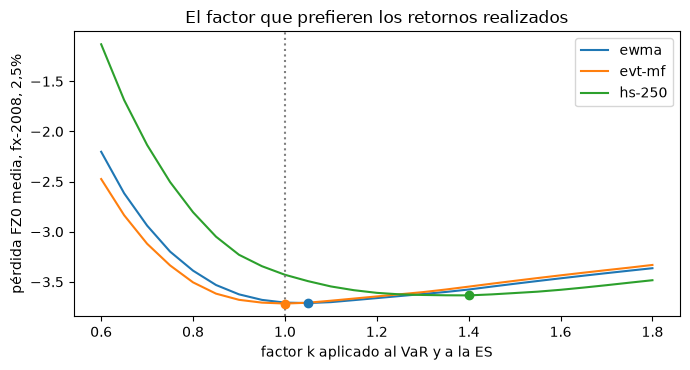

In [4]:
# FZ0 medio del VaR y la ES de tres modelos multiplicados por un factor k, y el factor que prefiere cada modelo
factors = np.linspace(0.6, 1.8, 25)
curves = {}
for model_id in ("ewma", "evt-mf", "hs-250"):
    v, e, level, eligible = book[model_id]
    curves[model_id] = np.array([fz0_loss(returns, k * v, k * e, 0.025).mean() for k in factors])
    best = int(np.argmin(curves[model_id]))
    print(f"{model_id:7s} factor 1.00: FZ0 medio {fz0_loss(returns, v, e, 0.025).mean():.4f} | mejor factor {factors[best]:.2f}: {curves[model_id][best]:.4f}")

fig, ax = plt.subplots(figsize=(7, 3.8))
for model_id, curve in curves.items():
    ax.plot(factors, curve, label=model_id)
    ax.scatter(factors[int(np.argmin(curve))], curve.min(), zorder=3)
ax.axvline(1.0, color="grey", linestyle=":")
ax.set_xlabel("factor k aplicado al VaR y a la ES")
ax.set_ylabel("pérdida FZ0 media, fx-2008, 2,5%")
ax.set_title("El factor que prefieren los retornos realizados")
ax.legend()
fig.tight_layout()
plt.show()

### Paso 3: Diebold-Mariano contra el campeón

Para decir que un modelo es mejor que otro, y no solo afortunado en esta ventana, Diebold y Mariano (1995) contrastan si la media del diferencial de pérdida $d_t = L_t^{A} - L_t^{B}$ es cero:

$$DM = \frac{\bar d}{\sqrt{\widehat{\mathrm{LRV}}/T}} \xrightarrow{d} N(0,1), \qquad \widehat{\mathrm{LRV}} = \hat\gamma_0 + 2\sum_{j=1}^{h}\left(1 - \tfrac{j}{h+1}\right)\hat\gamma_j$$

con $\hat\gamma_j$ las autocovarianzas muestrales de $d_t$ y $h$ los rezagos de Bartlett; para pronósticos a un paso la comparación versionada usa $h = 0$. Un $\bar d$ **negativo** significa que el modelo A tiene la pérdida más baja, así que es mejor. La función `diebold_mariano(loss_a, loss_b, lags)` del motor devuelve la diferencia media, el estadístico y el valor p normal bilateral. La celda encuentra el campeón con la regla del paso 5, compara cada otro modelo con él en FZ0 y en pérdida de tick, y pone el resultado junto a las filas versionadas.

In [5]:
# Campeón por la regla del paso 5, y luego Diebold-Mariano de cada otro modelo contra él, en FZ0 y en pérdida de tick
from riskvalidation.market.scoring import diebold_mariano


def champion_of(window, alpha, y):
    """Menor FZ0 medio entre los modelos elegibles con ES todos los días, y los puntajes de todos los modelos que tienen ES."""
    scores = {m: fz0_loss(y, v, e, alpha) for m, (v, e, level, eligible) in forecasts_of(window, alpha).items() if e is not None}
    pool = [m for m in scores if forecasts_of(window, alpha)[m][3]]
    return (min(pool, key=lambda m: scores[m].mean()) if pool else None), scores


for window in ("fx-2008", "rates-2022"):
    y = -np.array(docs[window]["outputs"]["grid"]["realised_loss"]["loss"])
    for alpha in (0.01, 0.025):
        champion, fz = champion_of(window, alpha, y)
        committed_champion = {c["alpha"]: c["model_id"] for c in docs[window]["outputs"]["comparison"]["champions"]}[alpha]
        book = forecasts_of(window, alpha)
        tick = {m: tick_loss(y, v, alpha) for m, (v, e, level, eligible) in book.items()}
        rows = {(r["model_id"], r["loss"]): r for r in docs[window]["outputs"]["comparison"]["dm"] if r["alpha"] == alpha}
        peor, compared, better = 0.0, 0, 0
        for model_id in book:
            if model_id == champion:
                continue
            for kind, series in (("fz0", fz), ("tick", tick)):
                row = rows[(model_id, kind)]
                if row["direction"] == "not-evaluated" or model_id not in series:
                    continue
                result = diebold_mariano(series[model_id], series[champion], 0)
                peor = max(peor, abs(result.statistic - row["dm_statistic"]), abs(result.p_value - row["p_value"]))
                compared += 1
                better += result.p_value < 0.05 and result.mean_diff < 0
        print(f"{window:11s} alfa {alpha:5.3f} | campeón {champion} (versionado {committed_champion}) | filas DM comparadas {compared} | mayor diferencia {peor:.1e} | "
              f"modelos significativamente mejores que el campeón: {better}")

fx-2008     alfa 0.010 | campeón caviar-es (versionado caviar-es) | filas DM comparadas 28 | mayor diferencia 4.7e-09 | modelos significativamente mejores que el campeón: 0
fx-2008     alfa 0.025 | campeón evt-mf (versionado evt-mf) | filas DM comparadas 29 | mayor diferencia 5.0e-09 | modelos significativamente mejores que el campeón: 0
rates-2022  alfa 0.010 | campeón ewma (versionado ewma) | filas DM comparadas 29 | mayor diferencia 4.6e-09 | modelos significativamente mejores que el campeón: 1
rates-2022  alfa 0.025 | campeón ewma (versionado ewma) | filas DM comparadas 29 | mayor diferencia 4.9e-09 | modelos significativamente mejores que el campeón: 0


### Paso 4: el conjunto de confianza de modelos

Diebold-Mariano compara dos modelos. El conjunto de confianza de modelos de Hansen, Lunde y Nason (2011) responde la pregunta que hace un validador sobre una escalera entera: ¿cuáles modelos **no se distinguen del mejor**? Parte con todos los modelos, contrasta la hipótesis de que tienen igual pérdida esperada y, mientras se rechaza, elimina el peor modelo, usando un bootstrap para la distribución nula; los modelos que sobreviven forman el conjunto, con confianza $1-\alpha_{MCS}$. Contraste usa el estadístico de rango ($T_R$), confianza de 90 por ciento, un bootstrap estacionario de 1.000 sorteos y la pérdida FZ0. Un modelo está en el conjunto cuando su valor p MCS es al menos 0,10. El motor lo calcula con `arch.bootstrap.MCS` (el extra opcional `market`, instalado en este entorno con `pandas`), con semilla: las mismas pérdidas y la misma semilla dan los mismos valores p. Dos ventanas versionan sus retornos realizados, `rates-2022` y `fx-2008`, así que el cuaderno **recalcula** sus conjuntos en ambos niveles desde los pronósticos versionados, con la semilla del cálculo (42), y los compara con los valores p versionados. En las otras tres los retornos están retenidos, las pérdidas FZ0 no se pueden formar, y el cuaderno **lee** los conjuntos versionados. La celda imprime, para las cinco ventanas al 1 por ciento, el tamaño del conjunto y los modelos que quedan fuera, y luego el recálculo.

In [6]:
# Los conjuntos de confianza de modelos versionados al 1% (FZ0, estadístico TR, confianza de 90%): tamaño del conjunto y modelos fuera de él
for window in NAMES:
    comparison = docs[window]["outputs"]["comparison"]
    mcs = [m for m in comparison["mcs"] if m["alpha"] == 0.01][0]
    outside = [(m["model_id"], round(m["p_value"], 3)) for m in mcs["members"] if not m["in_set"]]
    print(f"{window:15s} {mcs['statistic']} {mcs['confidence']:.0%} | {mcs['n_bootstrap']} sorteos, bloque {mcs['block_length']} | {mcs['n_in_set']} de {len(mcs['members'])} modelos en el conjunto")
    print(f"{'':15s} fuera del conjunto (valor p MCS): {outside}")

# Recalcular los conjuntos de las dos ventanas que versionan sus retornos (la semilla del cálculo, 42) y compararlos con los valores p versionados
from riskvalidation.market.scoring import model_confidence_set

for window in ("rates-2022", "fx-2008"):
    returns = -np.array(docs[window]["outputs"]["grid"]["realised_loss"]["loss"])
    for alpha in (0.01, 0.025):
        committed = [m for m in docs[window]["outputs"]["comparison"]["mcs"] if m["alpha"] == alpha][0]
        ids = [m["model_id"] for m in committed["members"]]
        book = forecasts_of(window, alpha)
        losses = np.column_stack([fz0_loss(returns, book[i][0], book[i][1], alpha) for i in ids])
        fresh = model_confidence_set(losses, committed["confidence"], committed["statistic"], committed["n_bootstrap"], committed["block_length"], 42)
        gap = max(abs(fresh.p_values[k] - m["p_value"]) for k, m in enumerate(committed["members"]))
        same = [ids[k] for k in fresh.members] == [m["model_id"] for m in committed["members"] if m["in_set"]]
        print(f"{window:11s} alfa {alpha:5.3f} | conjunto recalculado: {len(fresh.members)} de {len(ids)} modelos | mayor diferencia de los valores p MCS con los versionados: {gap:.1e} | mismo conjunto: {si_no(same)}")

equity-2007-09  TR 90% | 1000 sorteos, bloque 10 | 12 de 14 modelos en el conjunto
                fuera del conjunto (valor p MCS): [('dn-rolling', 0.077), ('gas-fz-2', 0.078)]
equity-2020     TR 90% | 1000 sorteos, bloque 10 | 14 de 14 modelos en el conjunto
                fuera del conjunto (valor p MCS): []
rates-2022      TR 90% | 1000 sorteos, bloque 10 | 14 de 14 modelos en el conjunto
                fuera del conjunto (valor p MCS): []
fx-2008         TR 90% | 1000 sorteos, bloque 10 | 13 de 14 modelos en el conjunto
                fuera del conjunto (valor p MCS): [('dn-rolling', 0.049)]
mixed-2023      TR 90% | 1000 sorteos, bloque 10 | 2 de 14 modelos en el conjunto
                fuera del conjunto (valor p MCS): [('hs-250', 0.0), ('hs-500', 0.0), ('awhs', 0.0), ('dn-rolling', 0.0), ('ewma', 0.0), ('egarch-t', 0.0), ('fhs', 0.0), ('evt-mf', 0.0), ('caviar-es', 0.0), ('gas-fz-1', 0.0), ('gas-fz-2', 0.0), ('gas-hybrid', 0.0)]
rates-2022  alfa 0.010 | conjunto recalculado:

### Paso 5: la regla del campeón

La escalera separa dos preguntas. La **elegibilidad** pregunta si un modelo es aceptable: no debe estar en rojo en Kupiec, en cobertura condicional ni en la prueba de Acerbi-Szekely en ninguno de los dos niveles (cuadernos 03 y 04). El **orden** pregunta cuál modelo aceptable pronostica mejor: la FZ0 media más baja, entre los modelos elegibles que tienen ES todos los días. Es el marco de backtest comparativo de Nolde y Ziegel (2017): un validador quiere saber si un retador supera al campeón, no solo si el campeón es rechazado. Una ventana puede no tener campeón: si ningún modelo elegible tiene ES todos los días no hay puntaje FZ0 que ordenar, y el documento lo dice en lugar de elegir uno. La celda lee los campeones versionados y el número de modelos elegibles en las cinco ventanas, y la FZ0 media del campeón.

In [7]:
# Modelos elegibles, campeones y FZ0 media del campeón en las cinco ventanas, como se versionan
print(f"{'ventana':15s} {'elegibles':>9s}  {'campeón 1%':14s} {'FZ0 1%':>8s}  {'campeón 2.5%':14s} {'FZ0 2.5%':>9s}")
for window in NAMES:
    doc = docs[window]
    champions = {c["alpha"]: c["model_id"] for c in doc["outputs"]["comparison"]["champions"]}
    scores = {}
    for alpha, champion in champions.items():
        scores[alpha] = None if champion is None else forecasts_of(window, alpha)[champion][2]["fz0_mean"]
    cell = lambda alpha: ("ninguno" if champions[alpha] is None else champions[alpha], "-" if scores[alpha] is None else f"{scores[alpha]:.3f}")
    print(f"{window:15s} {int(doc['impact']['eligible_models']['value']):9d}  {cell(0.01)[0]:14s} {cell(0.01)[1]:>8s}  {cell(0.025)[0]:14s} {cell(0.025)[1]:>9s}")
reasons = {"no eligible model has an ES on every day, so none has an FZ0 score to rank": "ningún modelo elegible tiene una ES todos los días, así que ninguno tiene una puntuación FZ0 que ordenar"}
reason = docs["equity-2007-09"]["outputs"]["comparison"]["champions"][0]["reason"]
print("motivo cuando no hay campeón:", reasons.get(reason, reason))

ventana         elegibles  campeón 1%       FZ0 1%  campeón 2.5%    FZ0 2.5%
equity-2007-09          0  ninguno               -  ninguno                -
equity-2020             4  fhs              -1.986  evt-mf            -2.364
rates-2022              4  ewma             -3.811  ewma              -4.002
fx-2008                10  caviar-es        -3.557  evt-mf            -3.716
mixed-2023             17  gjr-t            -4.439  gjr-t             -4.623
motivo cuando no hay campeón: ningún modelo elegible tiene una ES todos los días, así que ninguno tiene una puntuación FZ0 que ordenar


La última figura ordena los modelos de `fx-2008` al 1 por ciento por FZ0 media, desde los puntajes recalculados. Una barra se colorea según si el modelo está en el conjunto de confianza, y un rayado marca los modelos sacados por las compuertas de elegibilidad. El campeón es la barra más baja entre los elegibles con ES; un modelo con una barra más baja que no es elegible no es campeón, cualquiera sea su puntaje.

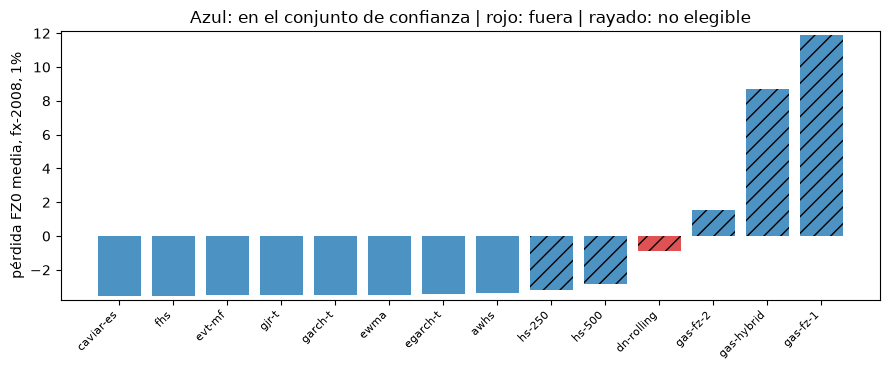

In [8]:
# Ordenar los modelos con ES en fx-2008 al 1% por FZ0 media, coloreados por el conjunto de confianza y rayados si no son elegibles
alpha = 0.01
book = forecasts_of("fx-2008", alpha)
inside = {m["model_id"]: m["in_set"] for m in [c for c in docs["fx-2008"]["outputs"]["comparison"]["mcs"] if c["alpha"] == alpha][0]["members"]}
ranked = sorted((fz0_loss(returns, v, e, alpha).mean(), m) for m, (v, e, level, eligible) in book.items() if e is not None)
fig, ax = plt.subplots(figsize=(9, 3.8))
for position, (score, model_id) in enumerate(ranked):
    ax.bar(position, score, color="tab:blue" if inside[model_id] else "tab:red", hatch="" if book[model_id][3] else "//", alpha=0.8)
ax.set_xticks(range(len(ranked)))
ax.set_xticklabels([m for s, m in ranked], rotation=45, ha="right", fontsize=8)
ax.set_ylim(min(s for s, m in ranked) - 0.2, max(s for s, m in ranked) + 0.2)
ax.set_ylabel("pérdida FZ0 media, fx-2008, 1%")
ax.set_title("Azul: en el conjunto de confianza | rojo: fuera | rayado: no elegible")
fig.tight_layout()
plt.show()

## Resultados

- **FZ0, a mano y con el motor.** Para `ewma` al 2,5 por ciento en `fx-2008` la FZ0 media es -3,706963 a mano, con el motor y en la fila versionada. La pérdida es -3,9515 en promedio en un día sin excepción y +3,7209 en los 8 días de excepción: el término de excepción es lo que castiga el puntaje. La FZ0 media y la pérdida de tick media de los 17 modelos en ambos niveles vuelven desde los arreglos con una diferencia máxima de 4,9e-09.
- **La consistencia, mostrada por escala.** Multiplicar el VaR y la ES de `evt-mf` por un factor $k$ da su FZ0 media más baja en $k = 1,00$ (-3,7162); para `ewma` en 1,05 (-3,7114 frente a -3,7070 sin escalar); para `hs-250` en 1,40 (-3,6350 frente a -3,4294 sin escalar). En la crisis de 2008 el pronóstico histórico habría necesitado números 40 por ciento mayores para puntuar mejor en su familia, y el puntaje lo dice con una brecha de 0,21.
- **Diebold-Mariano se reproduce.** Elegir el campeón por la regla y comparar con él a cada otro modelo da los campeones versionados (`caviar-es` al 1 por ciento y `evt-mf` al 2,5 por ciento en `fx-2008`; `ewma` en ambos niveles en `rates-2022`) y las 28 o 29 filas versionadas de cada caso con una diferencia máxima de 5,0e-09 en el estadístico y el valor p. En `fx-2008` ningún modelo es significativamente mejor que el campeón en ninguna de las dos pérdidas. En `rates-2022` al 1 por ciento uno lo es: `cf-rolling`, en la pérdida de tick (p 0,0438). No tiene ES y no es elegible, de modo que el orden solo por VaR puede diferir del orden por VaR y ES.
- **El conjunto de confianza.** Al 1 por ciento el conjunto tiene 12 de 14 modelos en `equity-2007-09` (fuera: `dn-rolling`, `gas-fz-2`, con valores p MCS cercanos a 0,08), 14 de 14 en `equity-2020` y `rates-2022`, 13 de 14 en `fx-2008` (fuera: `dn-rolling`, p 0,049) y 2 de 14 en `mixed-2023`, donde solo quedan `garch-t` y `gjr-t`. Una ventana con pocos días o poca pérdida separa mal a los modelos; `mixed-2023` los separa porque ningún modelo tiene una excepción en 64 días, el término indicador de FZ0 se anula, y el puntaje lo decide entonces cuán pequeña es la ES pronosticada. Los conjuntos se calcularon con el motor 0.7.0 y el paquete opcional `arch`; el recálculo de `rates-2022` y `fx-2008` en ambos niveles con el motor 0.8.1 devuelve los mismos conjuntos y los mismos valores p MCS (mayor diferencia 0,0e+00), y las otras tres ventanas se leen, no se recalculan, porque sus retornos están retenidos.
- **La regla del campeón en cinco ventanas.** `equity-2007-09` no tiene campeón porque ningún modelo es elegible (los 17 fallan una compuerta), y el archivo lo dice. `equity-2020` tiene 4 modelos elegibles y campeones `fhs` (FZ0 -1,986) al 1 por ciento y `evt-mf` (-2,364) al 2,5 por ciento. `rates-2022` tiene 4 elegibles y `ewma` en ambos niveles (-3,811, -4,002). `fx-2008` tiene 10 elegibles y `caviar-es` y `evt-mf` (-3,557, -3,716). `mixed-2023` tiene 17 elegibles y `gjr-t` en ambos niveles (-4,439, -4,623). El campeón cambia con la ventana, y en ninguna es una simple simulación histórica.

Lo que este cuaderno no muestra: ninguna prueba de un modelo a nivel de mesa (cuaderno 06) ni los modelos semiparamétricos dinámicos en detalle (cuaderno 07).

## Resumen

- El VaR y la ES se puntúan juntos porque el par es conjuntamente elicitable; la pérdida FZ0 es el miembro sin parámetros de esa clase. Su nivel no significa nada, sus diferencias entre modelos sí.
- Un puntaje consistente premia el pronóstico correcto: escalar un pronóstico muestra a qué distancia está cada modelo de su propia mejor escala, y un modelo que fue demasiado pequeño en una crisis prefiere un factor mayor.
- Diebold-Mariano convierte una diferencia de pérdida media en una prueba; un signo negativo significa que el primer modelo es mejor. Con un campeón fijado, cada otro modelo se compara con él en FZ0 y en pérdida de tick, y las filas versionadas vuelven desde los arreglos.
- El conjunto de confianza de modelos responde otra pregunta, cuáles modelos no se distinguen del mejor. Tiene semilla, así que las dos ventanas que versionan sus retornos se recalculan hasta los valores p versionados; las otras tres se leen, pues sus retornos están retenidos.
- El campeón se elige en dos pasos: elegibilidad por los backtests tradicionales, luego la FZ0 más baja entre los modelos elegibles con ES todos los días. Una ventana puede no tener campeón, y el documento lo dice.

**Qué probar después.** Elige otro par de ventana y nivel en el paso 3 y busca un modelo significativamente peor que el campeón en FZ0 e indistinguible en pérdida de tick; luego continúa con el cuaderno 06, que pasa de los modelos a las mesas.

## Referencias

- Gneiting, T. (2011), Making and evaluating point forecasts, Journal of the American Statistical Association 106(494). https://doi.org/10.1198/jasa.2011.r10138
- Fissler, T. y Ziegel, J. F. (2016), Higher order elicitability and Osband's principle, Annals of Statistics 44(4). https://doi.org/10.1214/16-AOS1439
- Patton, A. J., Ziegel, J. F. y Chen, R. (2019), Dynamic semiparametric models for expected shortfall (and value-at-risk), Journal of Econometrics 211(2). https://doi.org/10.1016/j.jeconom.2018.10.008
- Diebold, F. X. y Mariano, R. S. (1995), Comparing predictive accuracy, Journal of Business and Economic Statistics 13(3). https://doi.org/10.1080/07350015.1995.10524599
- Hansen, P. R., Lunde, A. y Nason, J. M. (2011), The model confidence set, Econometrica 79(2). https://doi.org/10.3982/ECTA5771
- Nolde, N. y Ziegel, J. F. (2017), Elicitability and backtesting: perspectives for banking regulation, Annals of Applied Statistics 11(4). https://doi.org/10.1214/17-AOAS1041